# Optical frequency combs through Calculus 2
### geometric series → comb teeth · f-2f · measuring a laser · exact-integer clockwork · inner products · laser safety

**In plain words.** A mode-locked laser fires identical light pulses at a steady rate $f_{\text{rep}}$.
In frequency, that pulse train is a **ruler**: hundreds of thousands of evenly spaced, perfectly
known optical frequencies (teeth). With it you can count the frequency of light directly and link
optical clocks to electronics. This work earned the 2005 Nobel Prize in Physics (Hall and Hänsch).

**The math is Calculus 2:**
* a train of pulses is a **geometric series**, whose sum is the comb;
* the teeth are **Fourier-series** terms;
* their orthogonality is an **integral**.

**Plan:**
1. derive the comb from the geometric series;
2. the carrier-envelope offset, and how f-2f measures it;
3. measure an unknown laser and resolve its tooth-number ambiguity;
4. build an optical-clock "clockwork" with exact integer arithmetic;
5. treat the comb teeth as an orthonormal basis: dimension and inner products;
6. ultrashort-pulse laser-safety arithmetic (ANSI Z136.1 context).

Every figure uses the Okabe–Ito colorblind-safe palette, distinguishes curves by line style as
well as color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
from fractions import Fraction
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import frequency_comb as fc
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. A pulse train is a geometric series

Take $N$ identical pulses spaced $T=1/f_{\text{rep}}$ apart, and let each pulse's carrier phase
slip by $\Delta\phi$ relative to the one before. By the Fourier shift theorem, the spectrum is
the single-pulse spectrum $A(f)$ times

$$\sum_{k=0}^{N-1}e^{ik(\Delta\phi-2\pi fT)}=\sum_{k=0}^{N-1}r^k,\qquad r=e^{ix}.$$

That's a geometric series. SymPy sums it and checks $|S|^2$ against the Dirichlet kernel:

In [2]:
S, residual = fc.comb_geometric_sum_symbolic()
display(sp.Eq(sp.Symbol("S"), S)); print("|S|^2 - sin^2(Nx/2)/sin^2(x/2) =", residual)
display(sp.Eq(sp.Symbol("f_n (peaks, x = 2 pi n)"), fc.comb_peak_frequencies_symbolic()))

    ⎧                 ⅈ⋅x    
    ⎪    N       for ℯ    = 1
    ⎪                        
    ⎪     ⅈ⋅N⋅x              
S = ⎨1 - ℯ                   
    ⎪──────────   otherwise  
    ⎪      ⅈ⋅x               
    ⎪ 1 - ℯ                  
    ⎩                        

|S|^2 - sin^2(Nx/2)/sin^2(x/2) = 0


Peaks occur wherever $x$ is a multiple of $2\pi$, which gives the comb equation

$$\boxed{f_n=n\,f_{\text{rep}}+f_{\text{ceo}}},\qquad f_{\text{ceo}}=\frac{\Delta\phi}{2\pi}f_{\text{rep}}.$$

The more pulses you add, the sharper each tooth gets: the width is about $f_{\text{rep}}/N$.

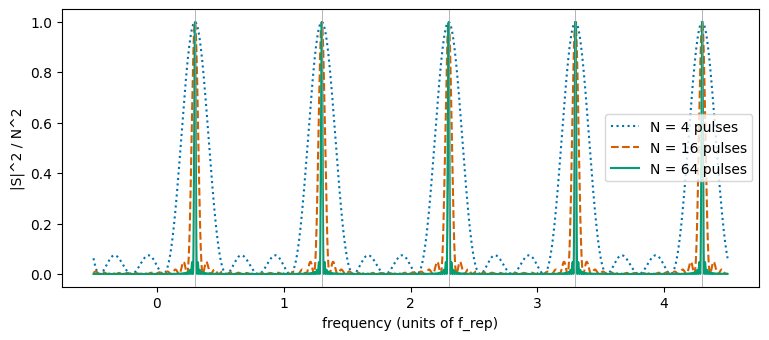

Figure description: normalized Dirichlet kernel for 4 (dotted), 16 (dashed), and 64 (solid) pulses. All peak at the same frequencies n + 0.3 (gray lines); more pulses make each tooth narrower and suppress the ripple between.


In [3]:
f_rep, f_ceo = 1.0, 0.3                                  # normalized units
f = np.linspace(-0.5, 4.5, 6000)
fig, ax = plt.subplots(figsize=(9, 3.6))
for N, ls in ((4, ":"), (16, "--"), (64, "-")):
    ax.plot(f, fc.comb_spectrum(f, f_rep, f_ceo, N) / N**2, ls=ls, label=f"N = {N} pulses")
for n in range(5): ax.axvline(n * f_rep + f_ceo, color="0.6", lw=0.5)
ax.set_xlabel("frequency (units of f_rep)"); ax.set_ylabel("|S|^2 / N^2"); ax.legend(); plt.show()
print("Figure description: normalized Dirichlet kernel for 4 (dotted), 16 (dashed), and 64 (solid) pulses. All peak at "
      "the same frequencies n + 0.3 (gray lines); more pulses make each tooth narrower and suppress the ripple between.")

Check against a real simulated pulse train. Generate 64 Gaussian pulses with a phase slip of
$0.3\times2\pi$, take the FFT, and confirm the strongest tooth lands on $nf_{\text{rep}}+f_{\text{ceo}}$:

strongest tooth 20.2969 MHz;  n f_rep + f_ceo = 20 x 1 MHz + 0.3 MHz = 20.3000 MHz


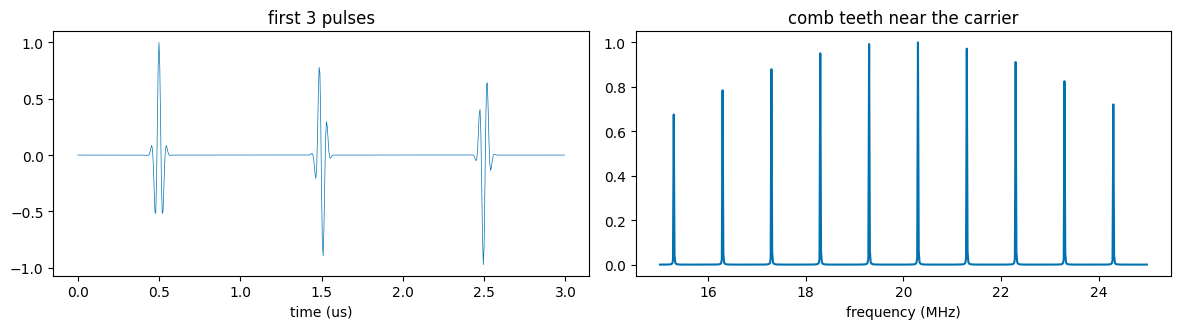

Figure description: left, three short pulses of a 20 MHz carrier; right, the spectrum is a row of sharp teeth spaced 1 MHz apart, offset 0.3 MHz from integer MHz values, under a broad envelope.


In [4]:
f_rep_s, dphi, fs = 1e6, 2*np.pi*0.3, 200e6
t, s = fc.simulate_pulse_train(64, f_rep_s, dphi, fs, f_carrier=20e6, pulse_fwhm_s=50e-9)
spec = np.abs(np.fft.rfft(s))**2; fr_ = np.fft.rfftfreq(len(s), 1/fs)
pk = fr_[np.argmax(spec)]; fceo_s = fc.ceo_from_slip(dphi, f_rep_s); n = round((pk - fceo_s)/f_rep_s)
print(f"strongest tooth {pk/1e6:.4f} MHz;  n f_rep + f_ceo = {n} x 1 MHz + {fceo_s/1e6:.1f} MHz = {(n*f_rep_s+fceo_s)/1e6:.4f} MHz")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(t[:int(3/f_rep_s*fs)]*1e6, s[:int(3/f_rep_s*fs)], lw=0.5); ax[0].set_xlabel("time (us)"); ax[0].set_title("first 3 pulses")
m = (fr_ > 15e6) & (fr_ < 25e6); ax[1].plot(fr_[m]/1e6, spec[m]/spec.max()); ax[1].set_xlabel("frequency (MHz)"); ax[1].set_title("comb teeth near the carrier")
plt.tight_layout(); plt.show()
print("Figure description: left, three short pulses of a 20 MHz carrier; right, the spectrum is a row of sharp teeth "
      "spaced 1 MHz apart, offset 0.3 MHz from integer MHz values, under a broad envelope.")

## 2. The carrier-envelope offset, and f-2f self-referencing

Inside the laser, the pulse envelope travels at the **group velocity** and the carrier at the
**phase velocity**. Each round trip, the carrier slips under the envelope, which is the same
dispersion physics as this repo's group-delay and phase-retrieval notebooks:

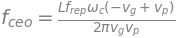

In [5]:
dphi_s, fceo_sym = fc.ceo_slip_symbolic()
display(sp.Eq(sp.Symbol("Delta phi"), dphi_s), sp.Eq(sp.Symbol("f_ceo"), fceo_sym))

$f_{\text{rep}}$ is easy to count on a fast photodiode. $f_{\text{ceo}}$ is invisible in the
intensity. The **f-2f** trick: if the comb spans an octave, frequency-double a low tooth and beat it
against a high tooth:

In [6]:
sp.Eq(sp.Symbol("2 f_n - f_2n"), fc.f2f_symbolic())

Every $n f_{\text{rep}}$ cancels, leaving $f_{\text{ceo}}$ alone as a radio-frequency beat.
Count it and you know every tooth exactly. This is called **self-referencing**.

## 3. Measuring an unknown laser: the integer ambiguity

Beat an unknown laser $\nu$ against the comb, and an RF counter reads the distance $f_b$ to the
nearest tooth. But **which** tooth ($n$) and **which side** ($\pm$) are lost. That's the same kind
of ambiguity as the $2\pi$ comb in atom-interferometer phase retrieval. Change $f_{\text{rep}}$
slightly and measure again; only the true $\nu$ is consistent with both readings:

In [7]:
nu = 194.1e12 + 12345.678e6                      # telecom-band laser (synthetic)
guess, span = nu + 2e9, 5e9                         # a wavemeter says "within +/- 5 GHz"
b1 = fc.beat_note(nu, 250e6, 35e6)
cand = fc.candidates(b1, 250e6, 35e6, guess, span)
surv, n1 = fc.resolve_with_two_reps(nu, 250e6, 250.01e6, 35e6, guess, span)
print(f"one measurement (f_b = {b1/1e6:.3f} MHz): {n1} candidate frequencies in the window")
print(f"two repetition rates (250 MHz and 250.01 MHz): survivors = {[f'{v/1e12:.9f} THz' for v in surv]}")
print(f"true frequency                                         = {nu/1e12:.9f} THz")

one measurement (f_b = 60.678 MHz): 81 candidate frequencies in the window
two repetition rates (250 MHz and 250.01 MHz): survivors = ['194.112345678 THz']
true frequency                                         = 194.112345678 THz


Same principle as the rest of the repo: **one intensity-type measurement is ambiguous, and a
second measurement with a known change breaks the ambiguity.** That's two dispersions in GS, two
interrogation times in the atom gyro, and two repetition rates here.

## 4. Optical clockwork, and why exact integers matter

Lock tooth $n$ to an optical clock at $\nu$. Then
$f_{\text{rep}}=(\nu-f_{\text{ceo}}-f_b)/n$ is a **microwave** frequency with the optical
clock's fractional stability. This is how optical clocks will redefine the second.

From `atomic_clock.ipynb`: a double can't hold an optical frequency to the last Hz. Compare a
double with Python's exact `Fraction`:

In [8]:
nu_str = "429228004229873.13"                  # an optical frequency with sub-Hz digits (illustrative)
n_tooth = 1716912
f_b = Fraction("-30770126.87")
fr = fc.frep_from_optical(nu_str, n_tooth, 35_000_000, f_b)
print("exact f_rep =", fr, "Hz")
err = Fraction(float(nu_str)) - Fraction(nu_str)
print(f"float64 stores nu as {Fraction(float(nu_str))} = {float(Fraction(float(nu_str))):.3f} Hz -> error {float(err)*1e3:.1f} mHz "
      f"= {abs(float(err))/float(nu_str):.2e} fractional")
print(f"\nstability transfer: a 1e-17 optical clock gives f_rep with {fc.stability_transfer(1e-17):.0e} fractional stability")

exact f_rep = 250000000 Hz
float64 stores nu as 3433824033838985/8 = 429228004229873.125 Hz -> error -5.0 mHz = 1.16e-17 fractional

stability transfer: a 1e-17 optical clock gives f_rep with 1e-17 fractional stability


The double's 5 mHz storage error is about $10^{-17}$ of the frequency, which is the size of
an optical clock's whole uncertainty budget. Frequency-metrology software keeps exact integers
(or offsets from a nominal value) for exactly this reason.

## 5. Comb teeth as an orthonormal basis

The teeth $e^{i2\pi nf_{\text{rep}}t}$ are orthogonal over one repetition period: the
Calculus 2 Fourier integral, here using the complex inner product
$\langle u,v\rangle=\int u^*v\,dt$ from `dimensions_inner_product`:

In [9]:
T = sp.symbols("T", positive=True)
print("<tooth 4, tooth 4> =", fc.tooth_orthogonality_symbolic(4, 4), "   <tooth 4, tooth 7> =", fc.tooth_orthogonality_symbolic(4, 7))
G = fc.tooth_gram_matrix([1, 2, 5, 9], 250e6)
print("numeric Gram matrix (explicit-loop inner product):\n", np.round(G.real, 10))
print(f"\ndimension of a 250 MHz comb spanning 40 THz: {fc.comb_dimension(40e12, 250e6):,} orthonormal teeth")

<tooth 4, tooth 4> = T    <tooth 4, tooth 7> = 0
numeric Gram matrix (explicit-loop inner product):
 [[ 1.  0. -0.  0.]
 [ 0.  1. -0.  0.]
 [-0. -0.  1.  0.]
 [ 0.  0.  0.  1.]]

dimension of a 250 MHz comb spanning 40 THz: 160,000 orthonormal teeth


An orthonormal basis lets you read any periodic signal's coefficients with one inner
product each. That's why a comb can do spectroscopy on 160,000 frequencies at once (dual-comb
spectroscopy).

**Contrast: the Minkowski "inner product."** The complex inner product is positive-definite: a
nonzero vector always has positive length. Spacetime's interval $s^2=c^2\Delta t^2-\Delta x^2$ is
**indefinite**. It can be positive, zero, or negative:

In [10]:
for dt, dx, what in ((1e-9, fc.C*1e-9, "a comb pulse traveling 1 ns"), (1.0, 1.0, "standing nearly still for 1 s"),
                     (1e-9, 10.0, "two events 10 m apart, 1 ns apart")):
    s2, kind = fc.minkowski_interval(dt, dx)
    print(f"{what:36s} s^2 = {s2:+.3e} m^2  ->  {kind}")

a comb pulse traveling 1 ns          s^2 = +0.000e+00 m^2  ->  light-like
standing nearly still for 1 s        s^2 = +8.988e+16 m^2  ->  time-like
two events 10 m apart, 1 ns apart    s^2 = -9.991e+01 m^2  ->  space-like


Light pulses travel along light-like intervals ($s^2=0$). Comb-based ranging (dual-comb
LIDAR) measures distance through exactly that relationship, $\Delta x=c\Delta t$.

## 6. Laser safety: average power hides peak power

A comb laser might average only 100 mW, but it concentrates that power into 100 fs pulses. The
engineering relationships (from `dgs.laser_safety`) are exact:

pulse energy 0.40 nJ;  peak power 3.53 kW  (35,256x the average)


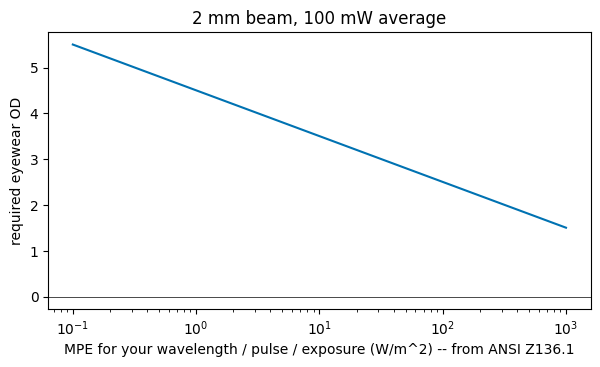

Figure description: required eyewear optical density falls linearly with the logarithm of the MPE; the curve shows how the answer depends on looking up the correct MPE rather than giving a single number.


In [11]:
P_avg, frep_l, tau = 0.1, 250e6, 100e-15
E = fc.pulse_energy(P_avg, frep_l); Pk = fc.peak_power(P_avg, frep_l, tau)
print(f"pulse energy {E*1e9:.2f} nJ;  peak power {Pk/1e3:.2f} kW  ({Pk/P_avg:,.0f}x the average)")
mpe = np.logspace(-1, 3, 200)                    # a RANGE of MPE values -- look up the real one
od = [fc.safety_summary(P_avg, frep_l, tau, 2e-3, m)["od_for_given_mpe"] for m in mpe]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogx(mpe, od, "-"); ax.axhline(0, c="k", lw=0.5)
ax.set_xlabel("MPE for your wavelength / pulse / exposure (W/m^2) -- from ANSI Z136.1"); ax.set_ylabel("required eyewear OD")
ax.set_title("2 mm beam, 100 mW average"); plt.show()
print("Figure description: required eyewear optical density falls linearly with the logarithm of the MPE; the curve "
      "shows how the answer depends on looking up the correct MPE rather than giving a single number.")

**Why there's no single OD number here.** The ANSI Z136.1 maximum permissible exposure (MPE)
depends on wavelength, pulse duration, repetition rate, and exposure time. Ultrashort repetitive
pulses get their own rules, which apply both single-pulse and average-power limits. The tables are
in the (copyrighted) standard, and the final answer belongs to your institution's Laser Safety
Officer. The plot shows how the OD follows once you have the right MPE.

**Non-beam hazards** that Z136.1 programs also cover:
* **Laser-generated airborne contaminants (LGAC):** fumes and particulates, including biological
  aerosols, when lasers ablate tissue or materials. This is the biohazard part.
* **Electrical** hazards from laser power supplies.
* **Fire** hazards from Class 4 beams.
* **Compressed gases and cryogens.**

Commercial self-referenced combs are laboratory instruments. Prices vary widely by configuration,
so ask vendors for quotes rather than relying on any figure here.

## 7. Summary

| idea | Calc 2 / physics tool | result |
|---|---|---|
| comb from pulse train | geometric series | $f_n=nf_{\text{rep}}+f_{\text{ceo}}$, width ≈ $f_{\text{rep}}/N$ |
| offset frequency | group vs phase velocity | $f_{\text{ceo}}=\Delta\phi f_{\text{rep}}/2\pi$; f-2f isolates it |
| laser measurement | integer ambiguity | 81 candidates → 1 with two repetition rates |
| clockwork | exact rationals | float64 error ~1e-17 ≈ optical clock budget |
| teeth | Fourier orthogonality | orthonormal basis; 160,000 dimensions |
| spacetime | indefinite form | light-like / time-like / space-like |
| safety | $E=P/f$, $P_{pk}\approx0.88E/\tau$ | 3.5 kW peak from 100 mW; OD needs the real MPE |

**Connections to the rest of the repo:**
* `atomic_clock` (the clock the comb divides down).
* `lockin_amplifier` (locking $f_{\text{ceo}}$ and the beat note).
* `gs_core` and `pulse_moments_group_delay` (dispersion sets $f_{\text{ceo}}$).
* Jalali's time-stretch (a comb's broadband pulses are what get stretched).

*Synthetic numbers; civilian education.*